In [55]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import ( LinearRegression ,
      Ridge ,
      Lasso )
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import (
      LabelEncoder,
      OneHotEncoder,
      StandardScaler,
      MinMaxScaler,
      RobustScaler,
      OrdinalEncoder,
      PolynomialFeatures,
      QuantileTransformer,

)
from sklearn.feature_selection import SelectFromModel
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
data = pd.read_csv("/content/sample_data/social_media_addiction_mental_wellbeing.csv")

In [5]:
data.shape


(1500, 30)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 30 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   User_ID                       1500 non-null   object 
 1   Age                           1500 non-null   int64  
 2   Gender                        1447 non-null   object 
 3   Occupation                    1455 non-null   object 
 4   Relationship_Status           1449 non-null   object 
 5   Primary_Platform              1447 non-null   object 
 6   Daily_Usage_Hours             1444 non-null   float64
 7   Platforms_Used_Count          1500 non-null   int64  
 8   Posts_Per_Week                1500 non-null   int64  
 9   Late_Night_Usage              1450 non-null   object 
 10  First_Check_Morning           1500 non-null   object 
 11  Notifications_Per_Day         1500 non-null   int64  
 12  FOMO_Score                    1445 non-null   float64
 13  Soc

In [7]:
data.describe()


,Age,Daily_Usage_Hours,Platforms_Used_Count,Posts_Per_Week,Notifications_Per_Day,FOMO_Score,Social_Comparison_Score,Validation_Seeking_Score,Scroll_Without_Purpose,Anxiety_Score,Depression_Score,Loneliness_Score,Self_Esteem_Score,Sleep_Quality_Score,Sleep_Hours,Productivity_Loss_Score,Offline_Relationship_Quality,Physical_Activity_Hrs_Week,Screen_Free_Time_Hrs,Mental_Wellbeing_Score
count,1500.000000,1444.000000,1500.000000,1500.000000,1500.000000,1445.000000,1449.000000,1442.000000,1500.000000,1452.000000,1445.000000,1445.000000,1431.000000,1432.000000,1438.000000,1449.000000,1430.000000,1449.000000,1440.000000,1500.000000
mean,29.372000,4.521399,3.236000,3.936000,60.244667,5.445882,5.495514,5.013107,5.449867,5.110537,4.562630,4.484429,5.519846,5.508659,6.557580,5.026570,5.482797,3.016494,3.025903,6.429733
std,8.550459,2.108319,1.682714,1.948273,33.150688,2.183914,2.041919,2.112417,2.083848,2.157587,2.199201,1.997623,1.993134,1.997842,1.380144,2.114049,2.045514,1.715963,1.691351,1.299288
min,15.000000,0.500000,1.000000,0.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,1.500000
25%,22.000000,3.100000,2.000000,3.000000,36.000000,4.000000,4.100000,3.600000,4.000000,3.700000,3.100000,3.100000,4.200000,4.100000,5.600000,3.600000,4.100000,1.800000,1.800000,5.500000
50%,29.000000,4.400000,3.000000,4.000000,59.000000,5.500000,5.500000,5.000000,5.500000,5.100000,4.500000,4.500000,5.600000,5.500000,6.600000,5.000000,5.400000,3.000000,3.000000,6.400000
75%,37.000000,5.900000,4.000000,5.000000,81.250000,7.000000,6.900000,6.500000,6.900000,6.600000,6.000000,5.900000,6.900000,6.900000,7.500000,6.400000,7.000000,4.200000,4.200000,7.300000
max,44.000000,12.000000,8.000000,12.000000,165.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,8.900000,10.300000,10.000000


In [8]:
data.nunique()

,0
User_ID,1500
Age,30
Gender,3
Occupation,4
Relationship_Status,3
Primary_Platform,6
Daily_Usage_Hours,100
Platforms_Used_Count,8
Posts_Per_Week,13
Late_Night_Usage,2


In [9]:
data.isnull().sum()


,0
User_ID,0
Age,0
Gender,53
Occupation,45
Relationship_Status,51
Primary_Platform,53
Daily_Usage_Hours,56
Platforms_Used_Count,0
Posts_Per_Week,0
Late_Night_Usage,50


In [10]:
data.columns

Index(['User_ID', 'Age', 'Gender', 'Occupation', 'Relationship_Status',
       'Primary_Platform', 'Daily_Usage_Hours', 'Platforms_Used_Count',
       'Posts_Per_Week', 'Late_Night_Usage', 'First_Check_Morning',
       'Notifications_Per_Day', 'FOMO_Score', 'Social_Comparison_Score',
       'Validation_Seeking_Score', 'Scroll_Without_Purpose',
       'Tried_To_Cut_Back', 'Failed_To_Cut_Back', 'Anxiety_Score',
       'Depression_Score', 'Loneliness_Score', 'Self_Esteem_Score',
       'Sleep_Quality_Score', 'Sleep_Hours', 'Productivity_Loss_Score',
       'Offline_Relationship_Quality', 'Physical_Activity_Hrs_Week',
       'Screen_Free_Time_Hrs', 'Mental_Wellbeing_Score', 'Addiction_Level'],
      dtype='object')

In [11]:
x = data.drop(columns=['User_ID','Mental_Wellbeing_Score','Addiction_Level',
    'Age', 'Posts_Per_Week', 'Sleep_Hours', 'Depression_Score'])

y = data['Mental_Wellbeing_Score']

In [14]:
y.head()

,Mental_Wellbeing_Score
0,7.3
1,4.1
2,5.6
3,4.3
4,6.6


In [15]:
x.head()

,Gender,Occupation,Relationship_Status,Primary_Platform,Daily_Usage_Hours,Platforms_Used_Count,Late_Night_Usage,First_Check_Morning,Notifications_Per_Day,FOMO_Score,...,Tried_To_Cut_Back,Failed_To_Cut_Back,Anxiety_Score,Loneliness_Score,Self_Esteem_Score,Sleep_Quality_Score,Productivity_Loss_Score,Offline_Relationship_Quality,Physical_Activity_Hrs_Week,Screen_Free_Time_Hrs
0,Male,Working Professional,In a Relationship,YouTube,2.9,4,No,Within 5 min,62,4.9,...,No,No,2.5,1.7,6.5,8.5,3.7,3.8,5.8,3.1
1,Male,Student,Married,Instagram,4.8,1,NaN,Within 5 min,111,4.2,...,Yes,Yes,4.0,7.0,7.5,7.8,4.0,1.8,0.9,3.3
2,Male,Student,In a Relationship,YouTube,NaN,4,No,Within 5 min,122,2.7,...,No,Yes,7.6,5.6,5.3,6.3,5.8,2.8,0.0,1.5
3,Female,Student,Married,Facebook,7.7,2,Yes,Within 5 min,48,3.9,...,NaN,No,3.3,5.6,1.4,3.9,5.5,3.6,1.0,3.9
4,Non-binary,Student,In a Relationship,TikTok,4.6,3,No,5-30 min,58,6.0,...,Yes,NaN,6.5,4.0,NaN,5.7,3.8,3.2,0.6,1.0


In [16]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)


In [17]:
numerical = x_train.select_dtypes(include=['float64', 'int64']).columns
categorical = x_train.select_dtypes(include=['object']).columns

In [18]:
numericimputer = SimpleImputer(strategy='median')
x_train[numerical] = numericimputer.fit_transform(x_train[numerical])
x_test[numerical] = numericimputer.transform(x_test[numerical])

In [22]:
catgerimpute = SimpleImputer(strategy='most_frequent')
x_train[categorical ]= catgerimpute.fit_transform(x_train[categorical])
x_test[categorical] = catgerimpute.transform(x_test[categorical])


In [58]:
encoder = OneHotEncoder(handle_unknown='ignore')
x_train_encoded = encoder.fit_transform(x_train[categorical])
x_test_encoded = encoder.transform(x_test[categorical])

In [50]:
#quantiling = QuantileTransformer (
    #n_quantiles=10,
    #output_distribution='normal',
    #random_state=42
#)
# it stopped cuz theres not too much outliers in data and it will decrease model's results instesd use scaling

In [41]:
scaler= StandardScaler()
x_train_scaled = scaler.fit_transform(x_train[numerical])
x_test_scaled = scaler.transform(x_test[numerical])

In [42]:
x.ndim
#serching for 2d cols x rows

2

In [43]:
ordinal_columns = ['First_Check_Morning']
yes_no_columns = ['Late_Night_Usage', 'Tried_To_Cut_Back', 'Failed_To_Cut_Back']
numerical = x_train.select_dtypes(include='number').columns.tolist()
categorical = [c for c in x_train.select_dtypes(exclude='number').columns
               if c not in ordinal_columns + yes_no_columns]

In [52]:

# columns_to_encode = ordinal_columns + yes_no_columns
# # 1)missing بالقيمة الأكتر تكراراً (fit علي train بس)
# imputer = SimpleImputer(strategy='most_frequent')
# x_train_filled = imputer.fit_transform(x_train[columns_to_encode])
# x_test_filled  = imputer.transform(x_test[columns_to_encode])

# enc = OrdinalEncoder(categories=[['After 30 min', '5-30 min', 'Within 5 min'],  # First_Check_Morning
#['No', 'Yes'],# Late_Night_Usage
#['No', 'Yes'],# Tried_To_Cut_Back
#['No', 'Yes']])# Failed_To_Cut_Back

# # 3) طبق index
# x_train_ordinal = pd.DataFrame(enc.fit_transform(x_train_filled),
#columns=columns_to_encode, index=x_train.index)
# x_test_ordinal  = pd.DataFrame(enc.transform(x_test_filled),
#columns=columns_to_encode, index=x_test.index)

In [64]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer

# Defining the preprocessor using the step logic created in prior cells
preprocessor = ColumnTransformer(
    transformers=[
        ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), numerical),
        ('ord', make_pipeline(SimpleImputer(strategy='most_frequent'), OrdinalEncoder(categories=[['After 30 min', '5-30 min', 'Within 5 min'],  # First_Check_Morning
 ['No', 'Yes'],                                  # Late_Night_Usage
 ['No', 'Yes'],                                  # Tried_To_Cut_Back
  ['No', 'Yes']                                   # Failed_To_Cut_Back
 ])), ordinal_columns + yes_no_columns),
        ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore')), categorical)
    ]
)

# Define and fit the pipeline model
model = make_pipeline(
    preprocessor,
    SelectFromModel(LassoCV(cv=2 , random_state=42)),
    LinearRegression()
)
model.fit(x_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['Daily_Usage_Hours',
                                                   'Platforms_Used_Count',
                                                   'Notifications_Per_Day',
                                                   'FOMO_Score',
                                                   'Social_Comparison_Score',
                                                   'Validation_Seeking_Score',
                                                   'Scroll_Without_Purpose',
                                                   'Anxiety_S...
                                                   'Failed_To_Cut_Back']),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Gender', 'Occupation',
                                                   'Relationship_Status',
                                                   'Primary_Platform'])])),
                ('selectfrommodel',
                 SelectFromModel(estimator=LassoCV(cv=2, random_state=42))),
                ('linearregression', LinearRegression())])

In [69]:
import seaborn as sns
sns.set_theme(style='whitegrid')

df = pd.read_csv("/content/sample_data/social_media_addiction_mental_wellbeing.csv")
target_name = 'Mental_Wellbeing_Score'

addiction_level = df['Addiction_Level']                       # للعرض فقط (leakage)، مش هيدخل الـ X
y = df[target_name]
x = df.drop(columns=['User_ID', 'Addiction_Level', target_name])

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

yes_no_columns = ['Late_Night_Usage', 'Tried_To_Cut_Back', 'Failed_To_Cut_Back']
first_check_order = ['After 30 min', '5-30 min', 'Within 5 min']

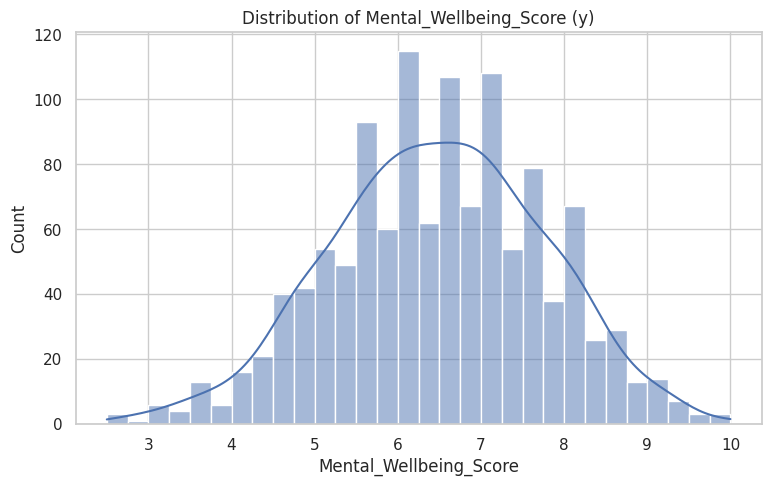

count    1200.00
mean        6.47
std         1.28
min         2.50
25%         5.60
50%         6.50
75%         7.40
max        10.00
Name: Mental_Wellbeing_Score, dtype: float64


In [70]:
plt.figure(figsize=(7, 4))
sns.histplot(y_train, kde=True, bins=30)
plt.title('Distribution of Mental_Wellbeing_Score (y)')
plt.show()
print(y_train.describe().round(2))

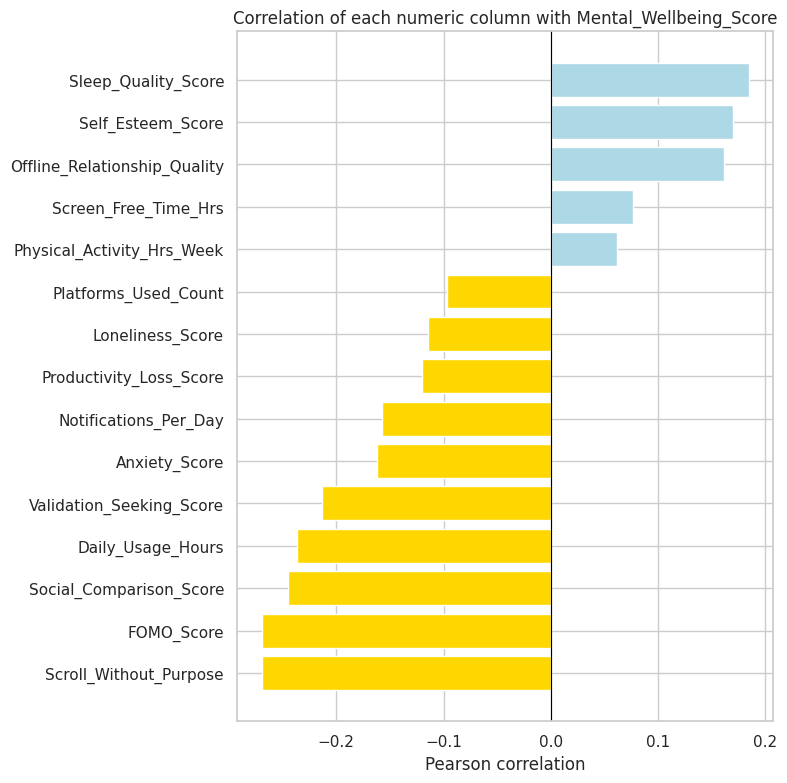

In [75]:
# Used the defined numerical columns list and target_name to compute the correlation matrix
numerical_only = df[numerical + [target_name]]
correlation_with_target = (numerical_only.corr()[target_name].drop(target_name).sort_values())
colors = ['gold' if value < 0 else 'lightblue' for value in correlation_with_target]
plt.figure(figsize=(8, 8))
plt.barh(correlation_with_target.index, correlation_with_target.values, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Correlation of each numeric column with Mental_Wellbeing_Score')
plt.xlabel('Pearson correlation')
plt.tight_layout(); plt.show()